<a href="https://colab.research.google.com/github/HeyFang/InterviewInsight.AI/blob/main/heart_monitor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [16]:
df = pd.read_csv("heart_disease_uci.csv")
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


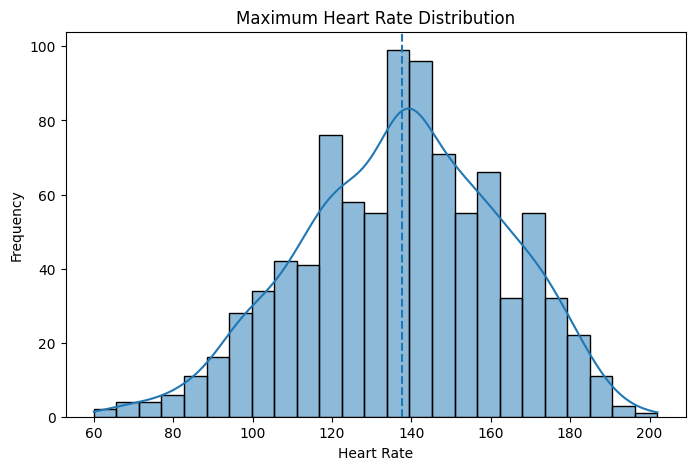

In [31]:
plt.figure(figsize=(8,5))

sns.histplot(df['thalch'], bins=25, kde=True)

plt.axvline(df['thalch'].mean(), linestyle='--')

plt.title("Maximum Heart Rate Distribution")
plt.xlabel("Heart Rate")
plt.ylabel("Frequency")

plt.show()

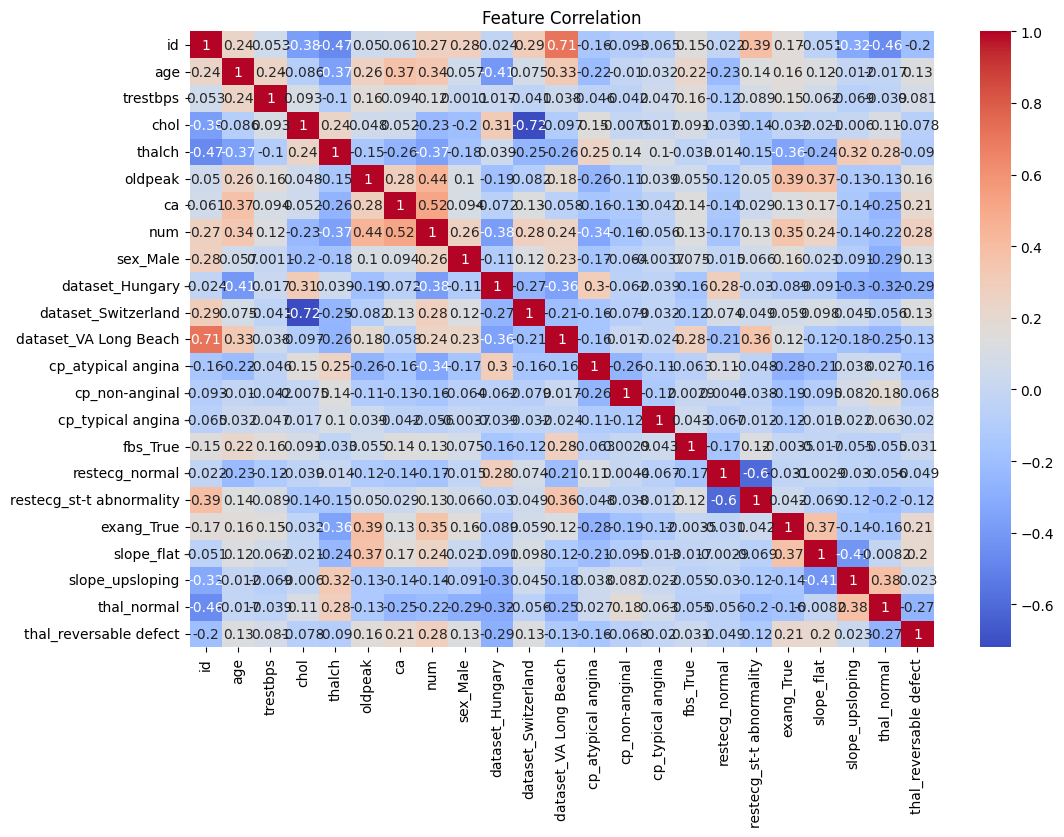

In [18]:
df_encoded = pd.get_dummies(df, drop_first=True)

plt.figure(figsize=(12,8))
sns.heatmap(df_encoded.corr(), cmap="coolwarm", annot=True)
plt.title("Feature Correlation")
plt.show()

In [19]:
df = df.fillna(df.mean(numeric_only=True))

df = pd.get_dummies(df, drop_first=True)

X = df.drop("num", axis=1)
y = df["num"]

y = (y > 0).astype(int)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [21]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [22]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [23]:
report = classification_report(y_test, y_pred, output_dict=True)

report_df = pd.DataFrame(report).transpose()

print("Accuracy:", accuracy_score(y_test, y_pred))

report_df

Accuracy: 0.8478260869565217


,precision,recall,f1-score,support
0,0.805195,0.826667,0.815789,75.000000
1,0.878505,0.862385,0.870370,109.000000
accuracy,0.847826,0.847826,0.847826,0.847826
macro avg,0.841850,0.844526,0.843080,184.000000
weighted avg,0.848623,0.847826,0.848123,184.000000


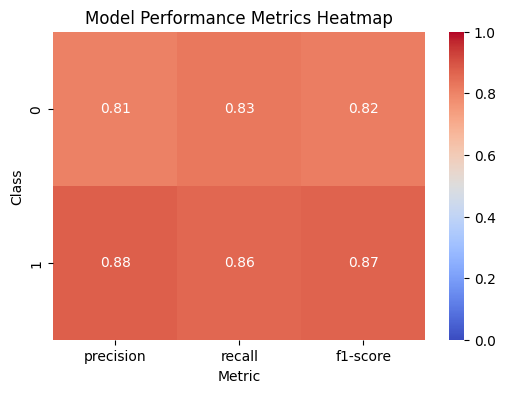

In [35]:
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

metrics = report_df.iloc[:2, :3]   # only class 0 and class 1

plt.figure(figsize=(6,4))
sns.heatmap(metrics, annot=True, cmap="coolwarm", vmin=0, vmax=1)

plt.title("Model Performance Metrics Heatmap")
plt.ylabel("Class")
plt.xlabel("Metric")

plt.show()

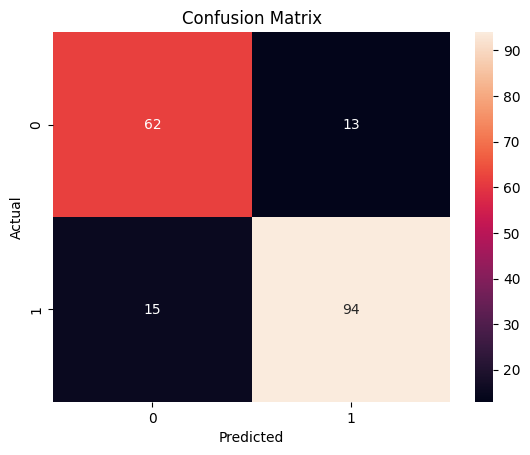

In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [26]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8478260869565217


In [43]:
from IPython.display import display, HTML

sample = X_test[0].reshape(1,-1)

prediction = model.predict(sample)
probability = model.predict_proba(sample)

risk_prob = round(probability[0][1]*100,2)

if prediction[0] == 1:
    status = "⚠️ High Risk"
    color = "red"
else:
    status = "✅ Low Risk"
    color = "green"

display(HTML(f"""
<div style="border:2px solid {color}; padding:15px; border-radius:10px; width:400px">
<h3 style="color:{color};">Heart Disease Prediction</h3>
<b>Status:</b> {status}<br>
<b>Probability of Disease:</b> {risk_prob}%<br><br>
</div>
"""))